# Nifty / Bank Nifty — Short Straddle-Strangle Options Strategy

**Strategy overview**
- Each trading day is classified (NEUTRAL / BULL / BEAR / STRANGLE / SKIP) using:
  - **Gift Nifty proxy** — opening gap vs previous close
  - **Previous day** — return, candle body direction
  - **RSI(14)**, **EMA(20)**, **ADX(14)**
  - **India VIX** — extreme-volatility skip filter
- Based on the signal, **short straddles or strangles** are sold:
  - `NEUTRAL` → ATM straddle
  - `BULL` → strangle skewed up (call further OTM)
  - `BEAR` → strangle skewed down (put further OTM)
  - `STRANGLE` → symmetric 1σ-OTM strangle
  - `SKIP` → no trade
- **Nifty 50**: weekly (Tuesday expiry)
- **Bank Nifty**: weekly (Wednesday) + monthly (last Thursday)
- Options priced with Black-Scholes using India VIX as implied volatility

## 0 · Setup

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Make sure the strategy package is importable from this notebook
REPO = Path('.').resolve()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams.update({
    'figure.figsize':  (13, 5),
    'axes.grid':       True,
    'grid.alpha':      0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

from strategy.data    import load_options_dataset
from strategy.signals import classify_trend
from strategy.options import bs_price, bs_greeks, select_strikes, NIFTY_LOT, BANKNIFTY_LOT
from strategy.backtest import OptionsBacktestConfig, OptionsBacktestEngine
from strategy.metrics  import (
    cagr, sharpe, sortino, max_drawdown, win_rate, profit_factor,
    generate_performance_report,
)

print('All imports OK ✓')

All imports OK ✓


## 1 · Configuration
Tweak these parameters, then re-run all cells below.

In [ ]:
# ── Date range ─────────────────────────────────────────────────────────────
START = '2020-01-01'
END   = '2025-05-31'   # set to None for today

# ── Capital ────────────────────────────────────────────────────────────────
CAPITAL = 2_000_000    # ₹20 lakh

# ── Instruments ────────────────────────────────────────────────────────────
TRADE_NIFTY      = True
TRADE_BANKNIFTY  = True
TRADE_BN_MONTHLY = True   # include BankNifty monthly expiry

# ── Entry timing ───────────────────────────────────────────────────────────
# 1 = day before expiry → too little premium, high gamma risk
# 3 = 3 days before → good balance of premium vs theta decay
ENTRY_DAYS_BEFORE = 3

# ── Risk filters ───────────────────────────────────────────────────────────
MAX_VIX        = 20.0    # skip if India VIX > this (20 = avoid pre-crash entries)
MAX_ADX        = 30.0    # skip if ADX(14) > this (trending market)
STOP_LOSS_MULT = 1.5     # exit when mark-to-market loss > N × premium; 0 = off

# ── Strike distance ────────────────────────────────────────────────────────
SIGMA_MULTIPLE = 1.0     # OTM distance for STRANGLE legs in daily-IV sigmas

# ── Lot sizes ──────────────────────────────────────────────────────────────
N_LOTS_NIFTY     = 1
N_LOTS_BANKNIFTY = 1

# ── Data ───────────────────────────────────────────────────────────────────
DATA_DIR = Path('data/cache')
REFRESH  = False       # set True to force re-download

end = END or pd.Timestamp.today().strftime('%Y-%m-%d')
print(f'Period: {START} → {end}  |  Capital: ₹{CAPITAL:,.0f}')
print(f'Entry: {ENTRY_DAYS_BEFORE} days before expiry  |  Max VIX: {MAX_VIX}  |  Stop: {STOP_LOSS_MULT}×')

## 2 · Load Data

In [3]:
dataset   = load_options_dataset(START, end, DATA_DIR, refresh=REFRESH)
nifty     = dataset['nifty']
banknifty = dataset['banknifty']
vix       = dataset['vix']
dates     = dataset['dates']

print(f"Trading days : {len(dates)}  ({dates[0].date()} → {dates[-1].date()})")
print(f"Nifty range  : {nifty['close'].min():.0f} – {nifty['close'].max():.0f}")
print(f"BankNifty    : {banknifty['close'].min():.0f} – {banknifty['close'].max():.0f}")
print(f"VIX range    : {vix.min():.1f} – {vix.max():.1f}  (mean {vix.mean():.1f})")

[DATA] Downloading Nifty 50, Bank Nifty, India VIX …
[DATA] Saved → data/cache/options_2020-01-01_2025-05-31.pkl  (1338 trading days)
Trading days : 1338  (2020-01-01 → 2025-05-30)
Nifty range  : 7610 – 26216
BankNifty    : 16917 – 55750
VIX range    : 10.1 – 83.6  (mean 18.1)


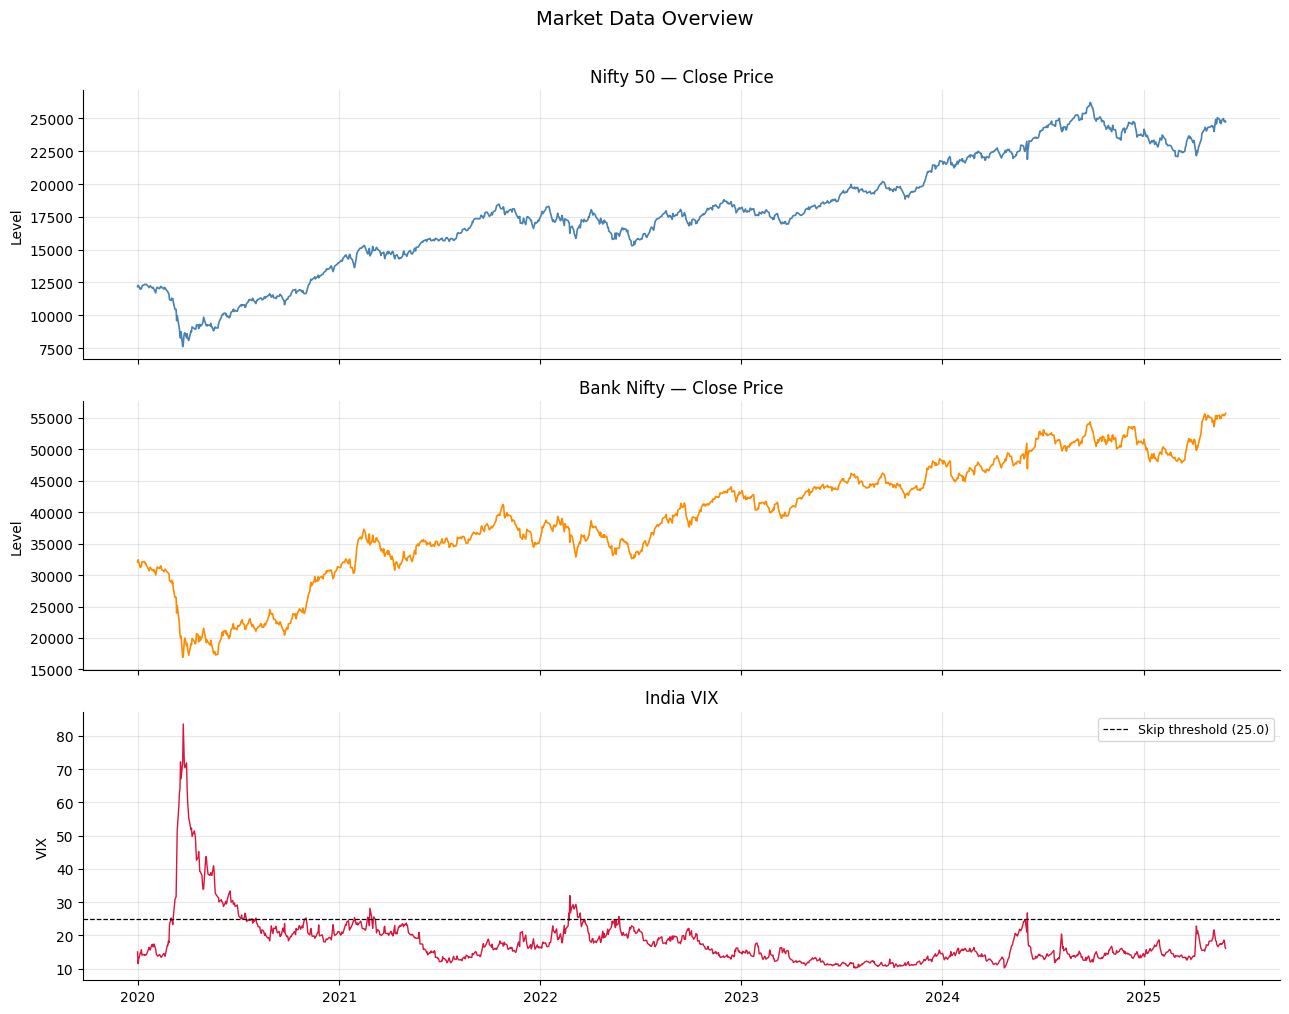

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].plot(nifty.index, nifty['close'], linewidth=1.2, color='steelblue')
axes[0].set_title('Nifty 50 — Close Price', fontsize=12)
axes[0].set_ylabel('Level')

axes[1].plot(banknifty.index, banknifty['close'], linewidth=1.2, color='darkorange')
axes[1].set_title('Bank Nifty — Close Price', fontsize=12)
axes[1].set_ylabel('Level')

axes[2].plot(vix.index, vix.values, linewidth=1, color='crimson')
axes[2].axhline(MAX_VIX, color='black', linestyle='--', linewidth=0.9, label=f'Skip threshold ({MAX_VIX})')
axes[2].set_title('India VIX', fontsize=12)
axes[2].set_ylabel('VIX')
axes[2].legend(fontsize=9)

fig.suptitle('Market Data Overview', fontsize=14, y=1.01)
fig.tight_layout()
plt.show()

## 3 · Trend Signal Classification

In [5]:
trend_nifty = classify_trend(
    nifty['open'], nifty['high'], nifty['low'], nifty['close'], vix,
    max_vix=MAX_VIX, max_adx=MAX_ADX,
)
trend_banknifty = classify_trend(
    banknifty['open'], banknifty['high'], banknifty['low'], banknifty['close'], vix,
    max_vix=MAX_VIX, max_adx=MAX_ADX,
)

print('Nifty 50 signal distribution:')
print(trend_nifty.value_counts().to_frame('count').assign(pct=lambda d: (d['count']/len(trend_nifty)*100).round(1)))
print()
print('Bank Nifty signal distribution:')
print(trend_banknifty.value_counts().to_frame('count').assign(pct=lambda d: (d['count']/len(trend_banknifty)*100).round(1)))

Nifty 50 signal distribution:
          count   pct
STRANGLE    509  38.0
SKIP        413  30.9
NEUTRAL     251  18.8
BULL        120   9.0
BEAR         45   3.4

Bank Nifty signal distribution:
          count   pct
STRANGLE    502  37.5
SKIP        341  25.5
NEUTRAL     262  19.6
BULL        153  11.4
BEAR         80   6.0


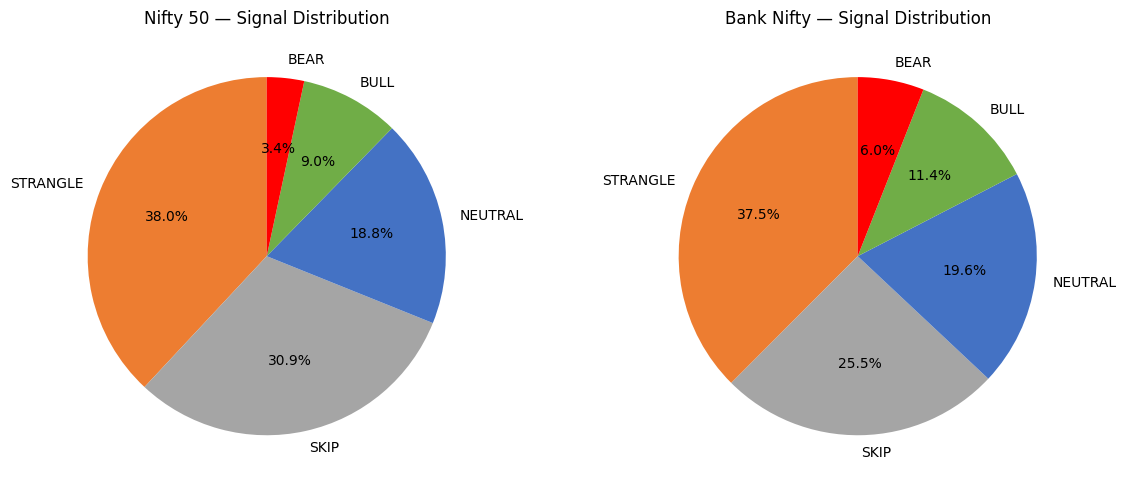

In [6]:
# Visualise signal distribution as pie charts
SIGNAL_COLORS = {
    'NEUTRAL':  '#4472C4',
    'BULL':     '#70AD47',
    'BEAR':     '#FF0000',
    'STRANGLE': '#ED7D31',
    'SKIP':     '#A5A5A5',
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, sig) in zip(axes, [('Nifty 50', trend_nifty), ('Bank Nifty', trend_banknifty)]):
    counts = sig.value_counts()
    colors = [SIGNAL_COLORS.get(s, '#cccccc') for s in counts.index]
    ax.pie(counts.values, labels=counts.index, colors=colors,
           autopct='%1.1f%%', startangle=90, textprops={'fontsize': 10})
    ax.set_title(f'{title} — Signal Distribution', fontsize=12)

fig.tight_layout()
plt.show()

In [7]:
# Show the last 20 trading days of signals + index levels
last20 = pd.DataFrame({
    'nifty_close':     nifty['close'],
    'vix':             vix,
    'nifty_signal':    trend_nifty,
    'banknifty_close': banknifty['close'],
    'bn_signal':       trend_banknifty,
}).tail(20)

last20.index = last20.index.strftime('%Y-%m-%d')
last20

,nifty_close,vix,nifty_signal,banknifty_close,bn_signal
Date,,,,,
2025-05-05,24461.150391,18.340000,STRANGLE,54919.500000,SKIP
2025-05-06,24379.599609,19.000000,STRANGLE,54271.398438,SKIP
2025-05-07,24414.400391,19.059999,STRANGLE,54610.898438,STRANGLE
2025-05-08,24273.800781,21.010000,STRANGLE,54365.648438,STRANGLE
2025-05-09,24008.000000,21.629999,STRANGLE,53595.250000,STRANGLE
2025-05-12,24924.699219,18.389999,NEUTRAL,55382.851562,STRANGLE
2025-05-13,24578.349609,18.200001,BULL,54940.851562,STRANGLE
2025-05-14,24666.900391,17.230000,STRANGLE,54801.300781,STRANGLE
2025-05-15,25062.099609,16.889999,STRANGLE,55355.601562,STRANGLE


## 4 · Options Pricing — Sanity Check
Quick look at how Black-Scholes prices look at current market levels.

In [8]:
latest_nifty  = float(nifty['close'].iloc[-1])
latest_bn     = float(banknifty['close'].iloc[-1])
latest_vix    = float(vix.iloc[-1]) / 100
daily_iv_nifty = latest_vix / np.sqrt(252)

print(f'Latest Nifty: {latest_nifty:.0f}   BankNifty: {latest_bn:.0f}   VIX: {latest_vix*100:.1f}')
print()

rows = []
for days in [1, 2, 3, 5, 7]:
    T = days / 252
    c = bs_price(latest_nifty, round(latest_nifty/50)*50, T, 0.068, latest_vix, 0.015, 'call')
    p = bs_price(latest_nifty, round(latest_nifty/50)*50, T, 0.068, latest_vix, 0.015, 'put')
    credit = (c + p) * NIFTY_LOT * N_LOTS_NIFTY
    rows.append({'Days to expiry': days, 'ATM Call (pts)': round(c,1), 'ATM Put (pts)': round(p,1),
                 'Total (pts)': round(c+p,1), 'Credit 1 lot (₹)': round(credit)})

print('Nifty ATM Straddle — premium at current VIX:')
pd.DataFrame(rows)

Latest Nifty: 24751   BankNifty: 55750   VIX: 16.1

Nifty ATM Straddle — premium at current VIX:


,Days to expiry,ATM Call (pts),ATM Put (pts),Total (pts),Credit 1 lot (₹)
0,1,103.0,97.1,200.1,5001
1,2,147.0,135.9,282.9,7073
2,3,181.4,165.1,346.5,8664
3,5,237.1,210.4,447.4,11186
4,7,283.3,246.2,529.4,13236


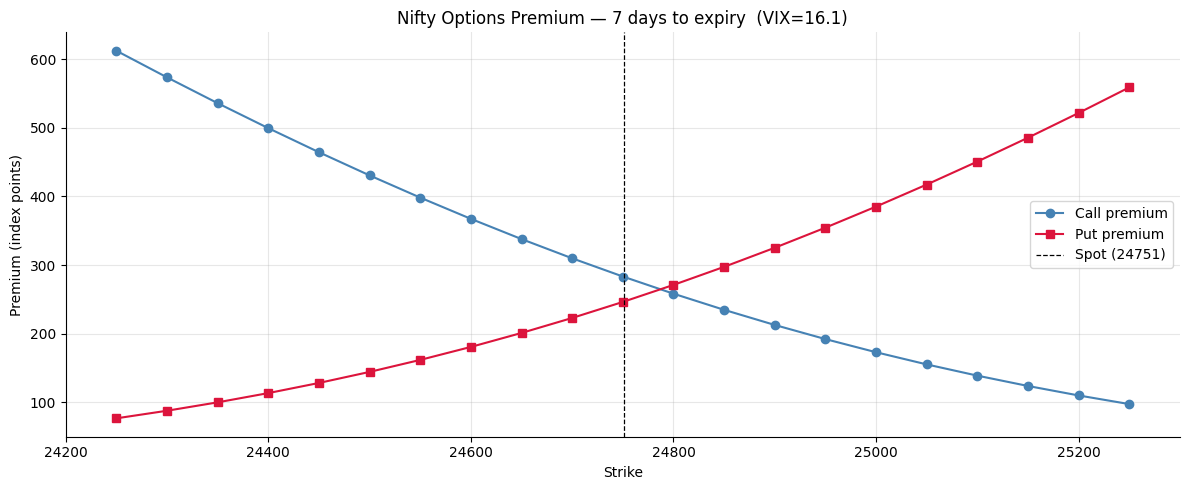

In [9]:
# Premium across strikes for a 7-day option (to see the smile shape)
atm = round(latest_nifty / 50) * 50
strikes = range(atm - 500, atm + 550, 50)
T = 7 / 252

calls = [bs_price(latest_nifty, k, T, 0.068, latest_vix, 0.015, 'call') for k in strikes]
puts  = [bs_price(latest_nifty, k, T, 0.068, latest_vix, 0.015, 'put')  for k in strikes]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(list(strikes), calls, 'o-', color='steelblue', label='Call premium')
ax.plot(list(strikes), puts,  's-', color='crimson',   label='Put premium')
ax.axvline(latest_nifty, color='black', linestyle='--', linewidth=0.9, label=f'Spot ({latest_nifty:.0f})')
ax.set_xlabel('Strike')
ax.set_ylabel('Premium (index points)')
ax.set_title(f'Nifty Options Premium — 7 days to expiry  (VIX={latest_vix*100:.1f})')
ax.legend()
plt.tight_layout()
plt.show()

## 5 · Run Backtest

In [10]:
cfg = OptionsBacktestConfig(
    initial_capital=CAPITAL,
    trade_nifty=TRADE_NIFTY,
    trade_banknifty=TRADE_BANKNIFTY,
    entry_days_before=ENTRY_DAYS_BEFORE,
    max_vix=MAX_VIX,
    max_adx=MAX_ADX,
    stop_loss_multiple=STOP_LOSS_MULT,
    sigma_multiple=SIGMA_MULTIPLE,
    n_lots_nifty=N_LOTS_NIFTY,
    n_lots_banknifty=N_LOTS_BANKNIFTY,
    trade_banknifty_monthly=TRADE_BN_MONTHLY,
)

engine  = OptionsBacktestEngine(cfg)
results = engine.run(nifty, banknifty, vix, trend_nifty, trend_banknifty)

trade_log     = results['trade_log']
equity_curve  = results['equity_curve']
daily_returns = results['daily_returns']

print(f'Total trades: {len(trade_log)}')
if not trade_log.empty:
    print(f'Date range  : {trade_log["entry_date"].min().date()} → {trade_log["exit_date"].max().date()}')
    print(f'Stop-loss exits: {(trade_log["exit_reason"]=="STOP_LOSS").sum()}')

Total trades: 429
Date range  : 2020-01-06 → 2025-05-29
Stop-loss exits: 0


## 6 · Performance Summary

In [11]:
mdd, mdd_start, mdd_end = max_drawdown(equity_curve)

summary = {
    'Initial Capital':          f'₹{CAPITAL:,.0f}',
    'Final Equity':             f'₹{equity_curve.dropna().iloc[-1]:,.0f}',
    'Total P&L':                f'₹{equity_curve.dropna().iloc[-1] - CAPITAL:,.0f}',
    'CAGR':                     f'{cagr(equity_curve)*100:.2f}%',
    'Sharpe Ratio':             f'{sharpe(daily_returns):.3f}',
    'Sortino Ratio':            f'{sortino(daily_returns):.3f}',
    'Max Drawdown':             f'{mdd*100:.2f}%',
    'Max DD Period':            f'{mdd_start.date()} → {mdd_end.date()}',
    'Total Trades':             len(trade_log),
    'Win Rate':                 f'{win_rate(trade_log)*100:.1f}%',
    'Profit Factor':            f'{profit_factor(trade_log):.2f}',
    'Avg Premium (pts)':        f'{trade_log["total_premium"].mean():.1f}' if not trade_log.empty else '-',
    'Total Costs (₹)':          f'₹{trade_log["costs"].sum():,.0f}' if not trade_log.empty else '₹0',
    'Stop-Loss %':              f'{(trade_log["exit_reason"]=="STOP_LOSS").mean()*100:.1f}%' if not trade_log.empty else '-',
}

s_df = pd.DataFrame(summary.items(), columns=['Metric', 'Value'])
print('='*52)
print('  PERFORMANCE SUMMARY')
print('='*52)
print(s_df.to_string(index=False))
print('='*52)

  PERFORMANCE SUMMARY
           Metric                   Value
  Initial Capital              ₹2,000,000
     Final Equity              ₹1,694,612
        Total P&L               ₹-305,388
             CAGR                  -3.02%
     Sharpe Ratio                  -1.549
    Sortino Ratio                  -0.738
     Max Drawdown                 -15.88%
    Max DD Period 2020-01-14 → 2025-04-24
     Total Trades                     429
         Win Rate                   64.1%
    Profit Factor                    0.54
Avg Premium (pts)                   118.4
  Total Costs (₹)                 ₹21,330
      Stop-Loss %                    0.0%


## 7 · Equity Curve & Drawdown

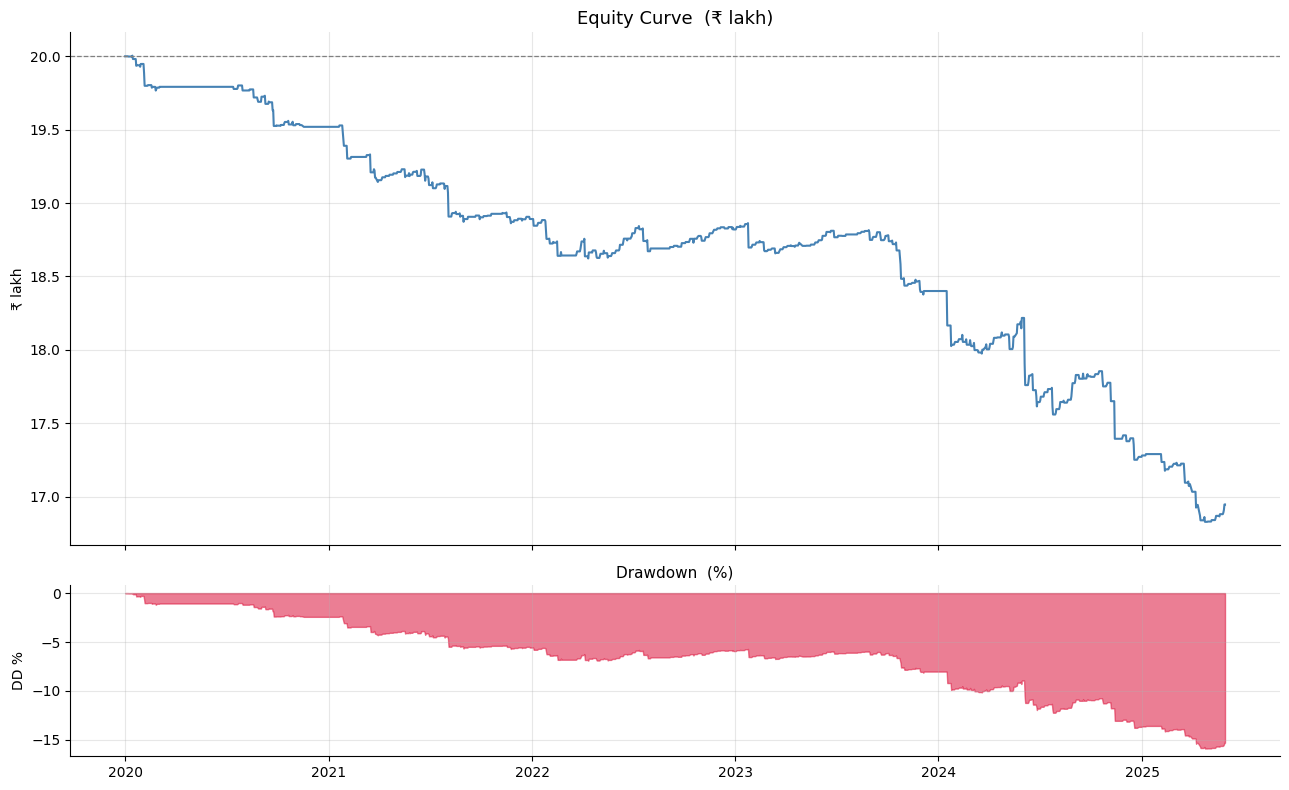

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                                 gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(equity_curve.index, equity_curve.values / 1e5, linewidth=1.5, color='steelblue')
ax1.axhline(CAPITAL / 1e5, color='gray', linestyle='--', linewidth=0.9)
ax1.set_title('Equity Curve  (₹ lakh)', fontsize=13)
ax1.set_ylabel('₹ lakh')

peak = equity_curve.cummax()
dd   = (equity_curve - peak) / peak * 100
ax2.fill_between(dd.index, dd.values, 0, color='crimson', alpha=0.55)
ax2.set_title('Drawdown  (%)', fontsize=11)
ax2.set_ylabel('DD %')

fig.tight_layout()
plt.show()

## 8 · Monthly P&L Heatmap

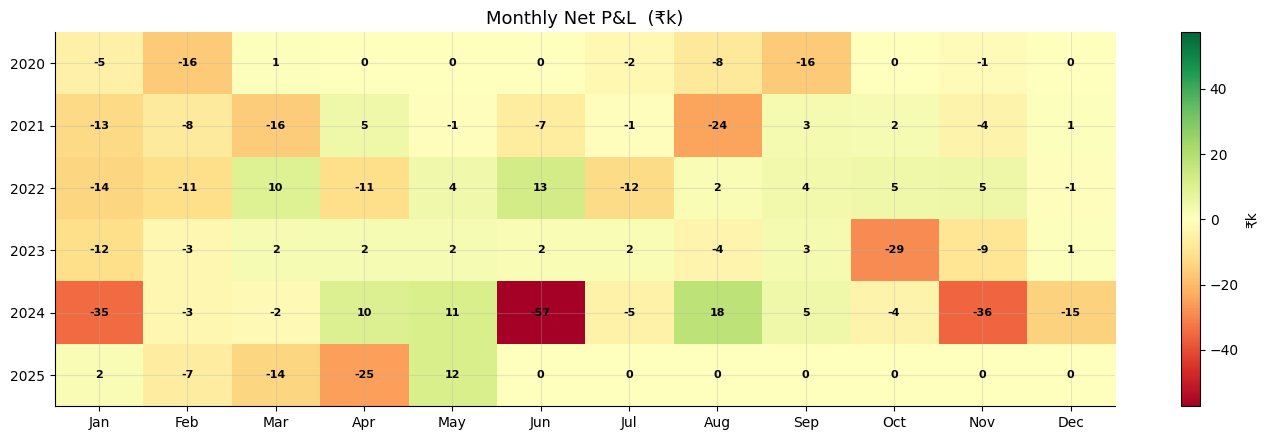

In [13]:
if not trade_log.empty:
    tl = trade_log.copy()
    tl['year']  = pd.to_datetime(tl['exit_date']).dt.year
    tl['month'] = pd.to_datetime(tl['exit_date']).dt.month
    pivot = tl.groupby(['year', 'month'])['net_pnl'].sum().unstack(fill_value=0) / 1e3

    vmax = max(abs(pivot.values.max()), abs(pivot.values.min()), 1)
    norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

    fig, ax = plt.subplots(figsize=(14, max(3, len(pivot) * 0.75)))
    im = ax.imshow(pivot.values, cmap='RdYlGn', norm=norm, aspect='auto')
    ax.set_xticks(range(pivot.shape[1]))
    ax.set_xticklabels([month_labels[m-1] for m in pivot.columns], fontsize=10)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=10)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            ax.text(j, i, f'{val:.0f}', ha='center', va='center',
                    fontsize=8, color='black', fontweight='bold')
    ax.set_title('Monthly Net P&L  (₹k)', fontsize=13)
    fig.colorbar(im, ax=ax, label='₹k')
    fig.tight_layout()
    plt.show()
else:
    print('No trades to display.')

## 9 · P&L by Trend Signal

              total_pnl  trades  avg_pnl  win_rate_pct  avg_premium
trend_signal                                                       
BEAR           -25389.0      33   -769.0          55.0        132.0
BULL           -64937.0      68   -955.0          66.0        120.0
NEUTRAL        -73732.0     105   -702.0          51.0        250.0
STRANGLE      -141331.0     223   -634.0          71.0         54.0



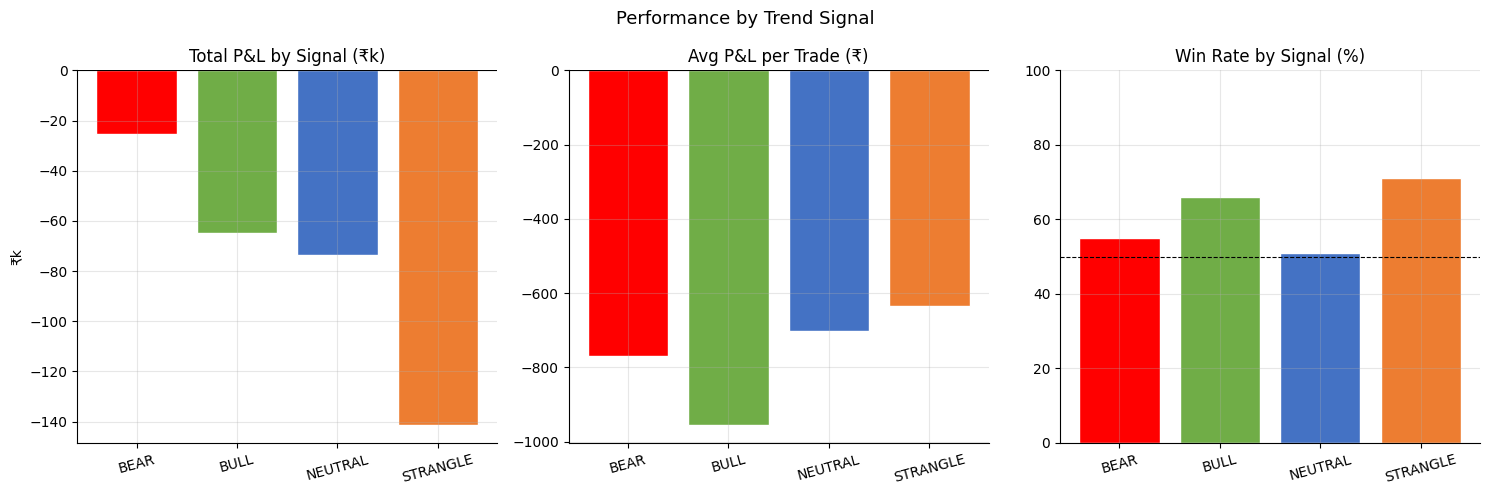

In [14]:
if not trade_log.empty:
    grp = trade_log.groupby('trend_signal').agg(
        total_pnl  =('net_pnl',  'sum'),
        trades     =('net_pnl',  'count'),
        avg_pnl    =('net_pnl',  'mean'),
        win_rate_pct=('net_pnl', lambda x: (x > 0).mean() * 100),
        avg_premium=('total_premium', 'mean'),
    ).round(0)

    print(grp.to_string())
    print()

    c = [SIGNAL_COLORS.get(s, '#A5A5A5') for s in grp.index]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].bar(grp.index, grp['total_pnl'] / 1e3, color=c, edgecolor='white')
    axes[0].axhline(0, color='black', linewidth=0.8)
    axes[0].set_title('Total P&L by Signal (₹k)')
    axes[0].set_ylabel('₹k')

    axes[1].bar(grp.index, grp['avg_pnl'], color=c, edgecolor='white')
    axes[1].axhline(0, color='black', linewidth=0.8)
    axes[1].set_title('Avg P&L per Trade (₹)')

    axes[2].bar(grp.index, grp['win_rate_pct'], color=c, edgecolor='white')
    axes[2].axhline(50, color='black', linestyle='--', linewidth=0.8)
    axes[2].set_ylim(0, 100)
    axes[2].set_title('Win Rate by Signal (%)')

    for ax in axes:
        ax.tick_params(axis='x', rotation=15)

    fig.suptitle('Performance by Trend Signal', fontsize=13)
    fig.tight_layout()
    plt.show()

## 10 · P&L Distribution

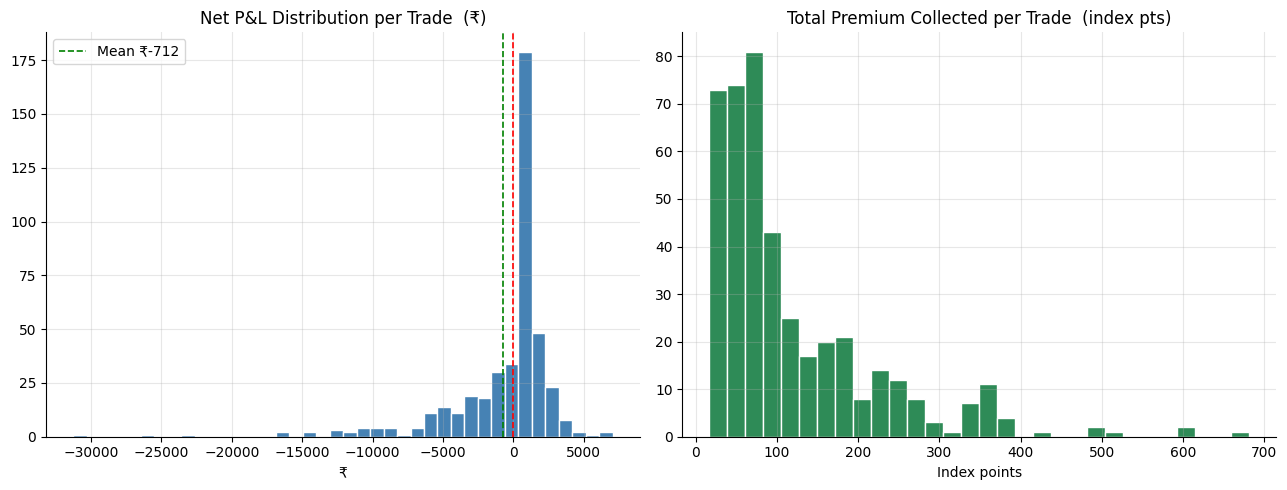

In [15]:
if not trade_log.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].hist(trade_log['net_pnl'], bins=40, color='steelblue', edgecolor='white')
    axes[0].axvline(0, color='red', linestyle='--', linewidth=1.2)
    axes[0].axvline(trade_log['net_pnl'].mean(), color='green', linestyle='--',
                    linewidth=1.2, label=f'Mean ₹{trade_log["net_pnl"].mean():,.0f}')
    axes[0].legend()
    axes[0].set_title('Net P&L Distribution per Trade  (₹)')
    axes[0].set_xlabel('₹')

    axes[1].hist(trade_log['total_premium'], bins=30, color='seagreen', edgecolor='white')
    axes[1].set_title('Total Premium Collected per Trade  (index pts)')
    axes[1].set_xlabel('Index points')

    fig.tight_layout()
    plt.show()

## 11 · VIX vs Trade Outcome

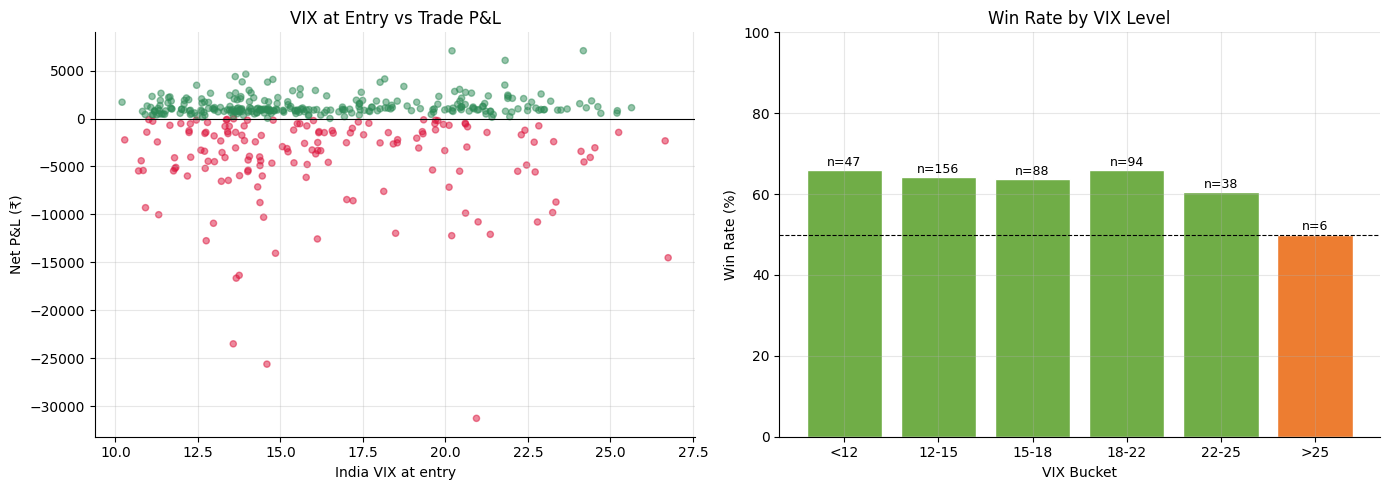

In [16]:
if not trade_log.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    colors = trade_log['net_pnl'].apply(lambda x: 'seagreen' if x > 0 else 'crimson')
    axes[0].scatter(trade_log['vix_entry'], trade_log['net_pnl'],
                    c=colors, alpha=0.5, s=20)
    axes[0].axhline(0, color='black', linewidth=0.8)
    axes[0].set_xlabel('India VIX at entry')
    axes[0].set_ylabel('Net P&L (₹)')
    axes[0].set_title('VIX at Entry vs Trade P&L')

    # VIX bucket win rate
    tl = trade_log.copy()
    tl['vix_bucket'] = pd.cut(tl['vix_entry'], bins=[0,12,15,18,22,25,100],
                               labels=['<12','12-15','15-18','18-22','22-25','>25'])
    bucket_stats = tl.groupby('vix_bucket', observed=True).agg(
        win_rate=('net_pnl', lambda x: (x > 0).mean() * 100),
        count=('net_pnl', 'count')
    )
    bcolors = ['#70AD47' if w >= 60 else '#ED7D31' if w >= 50 else '#FF0000'
               for w in bucket_stats['win_rate']]
    axes[1].bar(bucket_stats.index.astype(str), bucket_stats['win_rate'],
                color=bcolors, edgecolor='white')
    for i, (idx, row) in enumerate(bucket_stats.iterrows()):
        axes[1].text(i, row['win_rate'] + 1, f'n={int(row["count"])}',
                     ha='center', fontsize=9)
    axes[1].axhline(50, color='black', linestyle='--', linewidth=0.8)
    axes[1].set_ylim(0, 100)
    axes[1].set_xlabel('VIX Bucket')
    axes[1].set_ylabel('Win Rate (%)')
    axes[1].set_title('Win Rate by VIX Level')

    fig.tight_layout()
    plt.show()

## 12 · Nifty vs BankNifty Split

In [17]:
if not trade_log.empty:
    split = trade_log.groupby(['instrument', 'expiry_type']).agg(
        trades      =('net_pnl', 'count'),
        total_pnl   =('net_pnl', 'sum'),
        avg_pnl     =('net_pnl', 'mean'),
        win_rate    =('net_pnl', lambda x: f'{(x>0).mean()*100:.1f}%'),
        avg_premium =('total_premium', 'mean'),
        total_credit=('total_credit', 'sum'),
    ).round(0)
    split['total_pnl_str'] = split['total_pnl'].apply(lambda x: f'₹{x:,.0f}')
    split['avg_pnl_str']   = split['avg_pnl'].apply(lambda x: f'₹{x:,.0f}')
    print(split[['trades','total_pnl_str','avg_pnl_str','win_rate','avg_premium']]
          .rename(columns={'total_pnl_str':'Total P&L','avg_pnl_str':'Avg P&L'}).to_string())

                        trades  Total P&L  Avg P&L win_rate  avg_premium
instrument expiry_type                                                  
BANKNIFTY  MONTHLY          48   ₹-37,121    ₹-773    56.2%        161.0
           WEEKLY          193  ₹-250,085  ₹-1,296    59.1%        157.0
NIFTY      WEEKLY          188   ₹-18,182     ₹-97    71.3%         68.0


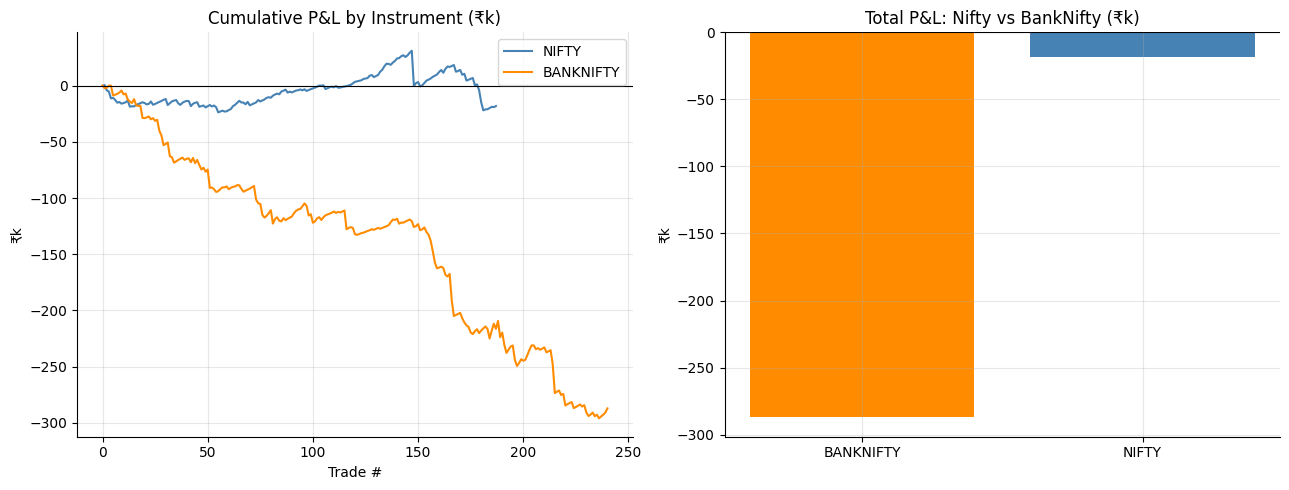

In [18]:
if not trade_log.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for inst, color in [('NIFTY', 'steelblue'), ('BANKNIFTY', 'darkorange')]:
        sub = trade_log[trade_log['instrument'] == inst].copy()
        if sub.empty:
            continue
        sub = sub.sort_values('exit_date')
        cum = sub['net_pnl'].cumsum()
        axes[0].plot(range(len(cum)), cum / 1e3, label=inst, color=color)

    axes[0].axhline(0, color='black', linewidth=0.8)
    axes[0].set_title('Cumulative P&L by Instrument (₹k)')
    axes[0].set_xlabel('Trade #')
    axes[0].set_ylabel('₹k')
    axes[0].legend()

    inst_totals = trade_log.groupby('instrument')['net_pnl'].sum() / 1e3
    axes[1].bar(inst_totals.index, inst_totals.values,
                color=['steelblue' if i == 'NIFTY' else 'darkorange' for i in inst_totals.index])
    axes[1].axhline(0, color='black', linewidth=0.8)
    axes[1].set_title('Total P&L: Nifty vs BankNifty (₹k)')
    axes[1].set_ylabel('₹k')

    fig.tight_layout()
    plt.show()

## 13 · Trade Log

In [19]:
if not trade_log.empty:
    display_cols = ['entry_date','exit_date','instrument','expiry_type','trade_type',
                    'trend_signal','call_strike','put_strike','total_premium',
                    'spot_entry','spot_exit','vix_entry','net_pnl','exit_reason']
    tl_display = trade_log[display_cols].copy()
    tl_display['entry_date'] = pd.to_datetime(tl_display['entry_date']).dt.date
    tl_display['exit_date']  = pd.to_datetime(tl_display['exit_date']).dt.date
    tl_display['net_pnl']    = tl_display['net_pnl'].apply(lambda x: f'₹{x:,.0f}')
    tl_display.tail(30)

## 14 · Parameter Sensitivity
Quick sweep over `max_vix` and `sigma_multiple` to see how they affect Sharpe ratio.

In [20]:
vix_levels    = [18, 20, 22, 25, 28]
sigma_levels  = [0.5, 0.75, 1.0, 1.25, 1.5]

results_grid = []
for mv in vix_levels:
    for sm in sigma_levels:
        tn = classify_trend(nifty['open'], nifty['high'], nifty['low'], nifty['close'],
                            vix, max_vix=mv, max_adx=MAX_ADX)
        tb = classify_trend(banknifty['open'], banknifty['high'], banknifty['low'], banknifty['close'],
                            vix, max_vix=mv, max_adx=MAX_ADX)
        c  = OptionsBacktestConfig(initial_capital=CAPITAL, max_vix=mv, sigma_multiple=sm,
                                    stop_loss_multiple=STOP_LOSS_MULT, entry_days_before=ENTRY_DAYS_BEFORE)
        r  = OptionsBacktestEngine(c).run(nifty, banknifty, vix, tn, tb)
        results_grid.append({
            'max_vix':       mv,
            'sigma_multiple': sm,
            'trades':         len(r['trade_log']),
            'cagr_pct':       round(cagr(r['equity_curve']) * 100, 2),
            'sharpe':         round(sharpe(r['daily_returns']), 3),
            'win_rate_pct':   round(win_rate(r['trade_log']) * 100, 1),
            'max_dd_pct':     round(max_drawdown(r['equity_curve'])[0] * 100, 2),
        })

grid_df = pd.DataFrame(results_grid)
print(grid_df.to_string(index=False))

 max_vix  sigma_multiple  trades  cagr_pct  sharpe  win_rate_pct  max_dd_pct
      18            0.50     296     -2.54  -1.507          54.7      -13.31
      18            0.75     296     -2.40  -1.487          57.8      -12.52
      18            1.00     296     -2.27  -1.501          63.5      -11.85
      18            1.25     296     -2.04  -1.449          67.2      -10.73
      18            1.50     296     -1.91  -1.438          69.9      -10.01
      20            0.50     342     -2.22  -1.281          56.7      -12.29
      20            0.75     342     -2.07  -1.256          59.6      -11.37
      20            1.00     342     -1.96  -1.270          64.6      -10.71
      20            1.25     342     -1.71  -1.195          69.0       -9.38
      20            1.50     342     -1.61  -1.194          71.6       -8.77
      22            0.50     387     -2.59  -1.375          57.1      -14.15
      22            0.75     387     -2.43  -1.357          59.7      -13.21

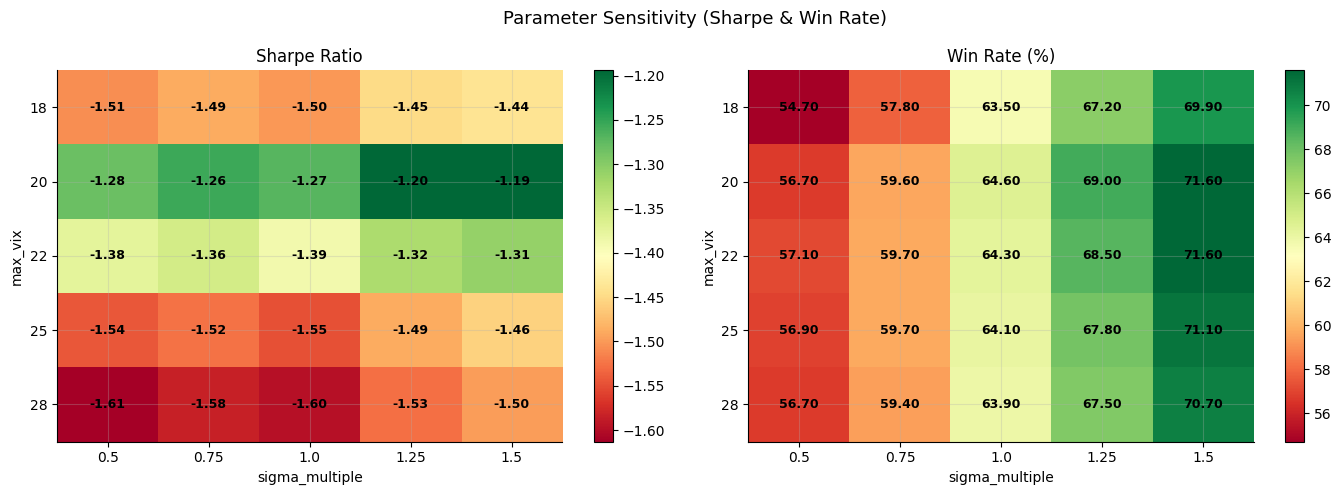

In [21]:
# Heatmap: Sharpe ratio across max_vix × sigma_multiple
sharpe_pivot = grid_df.pivot(index='max_vix', columns='sigma_multiple', values='sharpe')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, title, cmap in [
    (axes[0], 'sharpe',    'Sharpe Ratio',   'RdYlGn'),
    (axes[1], 'win_rate_pct', 'Win Rate (%)', 'RdYlGn'),
]:
    piv = grid_df.pivot(index='max_vix', columns='sigma_multiple', values=col)
    im  = ax.imshow(piv.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels(piv.index)
    ax.set_xlabel('sigma_multiple')
    ax.set_ylabel('max_vix')
    ax.set_title(title)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f'{piv.values[i,j]:.2f}', ha='center', va='center',
                    fontsize=9, color='black', fontweight='bold')
    fig.colorbar(im, ax=ax)

fig.suptitle('Parameter Sensitivity (Sharpe & Win Rate)', fontsize=13)
fig.tight_layout()
plt.show()

## 15 · Live Signal for Today
Prints the signal for the **next trading session** based on today's close.

In [22]:
today_nifty_signal = trend_nifty.iloc[-1]
today_bn_signal    = trend_banknifty.iloc[-1]
today_vix          = float(vix.iloc[-1])
today_nifty_close  = float(nifty['close'].iloc[-1])
today_bn_close     = float(banknifty['close'].iloc[-1])

from strategy.options import NIFTY_STRIKE_STEP, BANKNIFTY_STRIKE_STEP

daily_iv_nifty = (today_vix / 100) / np.sqrt(252) * 100
daily_iv_bn    = (today_vix / 100) / np.sqrt(252) * 100

nifty_ck, nifty_pk, nifty_tt = select_strikes(
    today_nifty_close, today_nifty_signal, daily_iv_nifty, NIFTY_STRIKE_STEP, SIGMA_MULTIPLE
)
bn_ck, bn_pk, bn_tt = select_strikes(
    today_bn_close, today_bn_signal, daily_iv_bn, BANKNIFTY_STRIKE_STEP, SIGMA_MULTIPLE
)

print('='*60)
print(f'  SIGNALS FOR NEXT SESSION  ({dates[-1].date()})')
print('='*60)
print(f'  India VIX          : {today_vix:.1f}')
print()
print(f'  NIFTY 50  ({today_nifty_close:.0f})')
print(f'    Signal            : {today_nifty_signal}')
if today_nifty_signal != 'SKIP':
    T = ENTRY_DAYS_BEFORE / 252
    iv = today_vix / 100
    from strategy.options import NIFTY_DIV_YIELD
    c = bs_price(today_nifty_close, nifty_ck, T, 0.068, iv, NIFTY_DIV_YIELD, 'call')
    p = bs_price(today_nifty_close, nifty_pk, T, 0.068, iv, NIFTY_DIV_YIELD, 'put')
    print(f'    Trade type        : Sell {nifty_tt}')
    print(f'    Sell CE strike    : {nifty_ck}  (premium ~{c:.1f} pts = ₹{c*NIFTY_LOT*N_LOTS_NIFTY:,.0f})')
    print(f'    Sell PE strike    : {nifty_pk}  (premium ~{p:.1f} pts = ₹{p*NIFTY_LOT*N_LOTS_NIFTY:,.0f})')
    print(f'    Total credit      : ~{c+p:.1f} pts = ₹{(c+p)*NIFTY_LOT*N_LOTS_NIFTY:,.0f}')
else:
    print(f'    → No trade (VIX or ADX filter triggered)')

print()
print(f'  BANK NIFTY  ({today_bn_close:.0f})')
print(f'    Signal            : {today_bn_signal}')
if today_bn_signal != 'SKIP':
    from strategy.options import BANKNIFTY_DIV_YIELD
    c = bs_price(today_bn_close, bn_ck, T, 0.068, iv, BANKNIFTY_DIV_YIELD, 'call')
    p = bs_price(today_bn_close, bn_pk, T, 0.068, iv, BANKNIFTY_DIV_YIELD, 'put')
    print(f'    Trade type        : Sell {bn_tt}')
    print(f'    Sell CE strike    : {bn_ck}  (premium ~{c:.1f} pts = ₹{c*BANKNIFTY_LOT*N_LOTS_BANKNIFTY:,.0f})')
    print(f'    Sell PE strike    : {bn_pk}  (premium ~{p:.1f} pts = ₹{p*BANKNIFTY_LOT*N_LOTS_BANKNIFTY:,.0f})')
    print(f'    Total credit      : ~{c+p:.1f} pts = ₹{(c+p)*BANKNIFTY_LOT*N_LOTS_BANKNIFTY:,.0f}')
else:
    print(f'    → No trade (VIX or ADX filter triggered)')

print('='*60)
print('  NOTE: Verify strikes on your broker before trading.')
print('  Replace the open-gap proxy with actual Gift Nifty')
print('  data from your terminal before 09:00 IST.')
print('='*60)

  SIGNALS FOR NEXT SESSION  (2025-05-30)
  India VIX          : 16.1

  NIFTY 50  (24751)
    Signal            : NEUTRAL
    Trade type        : Sell STRADDLE
    Sell CE strike    : 24750  (premium ~103.0 pts = ₹2,575)
    Sell PE strike    : 24750  (premium ~97.1 pts = ₹2,427)
    Total credit      : ~200.1 pts = ₹5,001

  BANK NIFTY  (55750)
    Signal            : NEUTRAL
    Trade type        : Sell STRADDLE
    Sell CE strike    : 55700  (premium ~257.8 pts = ₹3,867)
    Sell PE strike    : 55700  (premium ~195.3 pts = ₹2,929)
    Total credit      : ~453.1 pts = ₹6,796
  NOTE: Verify strikes on your broker before trading.
  Replace the open-gap proxy with actual Gift Nifty
  data from your terminal before 09:00 IST.
